In [1]:
import pandas as pd
import numpy as np
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV

Próximo passo: desnormalizar e verificar os resultados reais

Se eu achar uma vez que rodou que deu um resultado legal: posso salvar a randomseed e não perder o resultado.

Também posso salvar o modelo em si.

In [2]:
def prepara_df(tipo):
    local = 'C:\\Users\\ymarc\\OneDrive\\Desktop\\ITA - 2025\\Mestrado\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'

    if tipo=='treinamento': files = ['050', '300', '400']
    else: files = ['150']
    
    all_dfs = [pd.read_excel(local + file + '.xls').iloc[1:] for file in files]
    for i, item in enumerate(all_dfs): item['H'] = float(files[i])
    df = pd.concat(all_dfs, ignore_index=True)
    imputer.fit(df)
    return df

In [3]:
def separa_train_test():
    # Carrega os dados de treinamento ('050', '300', '400')
    dados_treinamento = prepara_df('treinamento')
    
    # Carrega os dados de teste ('150')
    Test_set = prepara_df('teste')

    # Separa o conjunto de treinamento em treino e validação
    Train_set, Val_set = train_test_split(dados_treinamento, test_size=0.2, random_state=42)
    
    return Train_set, Test_set, Val_set

In [39]:
# def escala(Train_set, Test_set, Val_set):
#     scaler = MinMaxScaler()
#     scaler.fit(Train_set)
#     Train_set_scaled = scaler.transform(Train_set)
#     Test_set_scaled = scaler.transform(Test_set)
#     Val_set_scaled = scaler.transform(Val_set)

#     return Train_set_scaled, Test_set_scaled, Val_set_scaled

In [38]:
# def padroniza_sets(Train_set, Test_set, Val_set):
#     # Seleciona características relevantes aos vetores de entrada e saída
#     X_train_scaled = np.delete(Train_set, [0,8,9,10,11,12], axis=1)
#     Y_train_scaled = np.delete(Train_set, [0,1,2,3,4,5,6,7,9,11,12], axis=1)

#     X_test_scaled = np.delete(Test_set, [0,8,9,10,11,12], axis=1)
#     Y_test_scaled = np.delete(Test_set, [0,1,2,3,4,5,6,7,9,11,12], axis=1)

#     X_val_scaled = np.delete(Val_set, [0,8,9,10,11,12], axis=1)
#     Y_val_scaled = np.delete(Val_set, [0,1,2,3,4,5,6,7,9,11,12], axis=1)

#     # Transforma os arrays em vetores de floats
#     X_train_scaled = np.array(X_train_scaled, dtype=np.float64)
#     Y_train_scaled = np.array(Y_train_scaled, dtype=np.float64)

#     X_test_scaled = np.array(X_test_scaled, dtype=np.float64)
#     Y_test_scaled = np.array(Y_test_scaled, dtype=np.float64)

#     X_val_scaled = np.array(X_val_scaled, dtype=np.float64)
#     Y_val_scaled = np.array(Y_val_scaled, dtype=np.float64)
    
#     return X_train_scaled, Y_train_scaled, X_test_scaled, Y_test_scaled, X_val_scaled, Y_val_scaled

In [6]:
def preparar_e_escalar_dados(train_set, test_set, val_set):
    """
    Esta função separa features (X) e alvos (Y), e então escala cada um com um scaler dedicado.
    Ela retorna os dados escalados e os scalers para uso futuro (como a desnormalização).
    """
    # Separar X e Y para cada conjunto de dados
    # Features (X)
    X_train = np.delete(train_set.values, [0,8,9,10,11,12], axis=1) # Exclui as colunas alvo
    X_test = np.delete(test_set.values, [0,8,9,10,11,12], axis=1)
    X_val = np.delete(val_set.values, [0,8,9,10,11,12], axis=1)

    # Alvos (Y)
    Y_train = np.delete(train_set.values, [0,1,2,3,4,5,6,7,9,11,12], axis=1) # Exclui as colunas alvo
    Y_test = np.delete(test_set.values, [0,1,2,3,4,5,6,7,9,11,12], axis=1)
    Y_val = np.delete(val_set.values, [0,1,2,3,4,5,6,7,9,11,12], axis=1)
    # Y_train = train_set.values[:, [0,1,2,3,4,5,6,7,9,11,12]]
    # Y_test = test_set.values[:, [0,1,2,3,4,5,6,7,9,11,12]]
    # Y_val = val_set.values[:, [0,1,2,3,4,5,6,7,9,11,12]]

    # 2. Criar e treinar os scalers
    scaler_X = MinMaxScaler()
    scaler_Y = MinMaxScaler()

    # Ajustar os scalers APENAS com os dados de TREINO
    X_train_scaled = scaler_X.fit_transform(X_train)
    Y_train_scaled = scaler_Y.fit_transform(Y_train)

    # 3. Aplicar a transformação aos outros conjuntos
    X_test_scaled = scaler_X.transform(X_test)
    Y_test_scaled = scaler_Y.transform(Y_test)
    
    X_val_scaled = scaler_X.transform(X_val)
    Y_val_scaled = scaler_Y.transform(Y_val)
    
    # Empacota os dados e os scalers para retorno
    dados_escalados = (X_train_scaled, Y_train_scaled, X_test_scaled, Y_test_scaled, X_val_scaled, Y_val_scaled)
    scalers = (scaler_X, scaler_Y)
    
    return dados_escalados, scalers

In [7]:
def constroi_modelo():
    model = keras.Sequential(
        [
            layers.Dense(10, input_shape=(7,), activation="relu", name='oculta1'),
            layers.Dense(10, activation="relu", name='oculta2'),
            layers.Dense(2, name='saida'),
        ]
    )
    model.compile(loss="mae", optimizer=Adam(learning_rate=1e-3))
    
    return model

Melhores Parâmetros:

    {'batch_size': 32, 'epochs': 60, 'model__learning_rate': 0.0001, 'model__neurons': 60, 'model__optimizer': 'adam'}

Melhor Score (MAE Negativo): -0.0009

Isso equivale a um Erro Absoluto Médio (MAE) de: 0.0009

In [9]:
def constroi_modelo_tunable(neurons=40, optimizer='adam', learning_rate=0.0001):
    model = keras.Sequential([
        layers.Dense(neurons, input_shape=(7,), activation="relu", name='oculta1'),
        layers.Dense(neurons, activation="relu", name='oculta2'),
        layers.Dense(2, name='saida') # Camada de saída para regressão
    ])
    
    # Seleciona o otimizador com base no parâmetro
    if optimizer == 'adam':
        opt = Adam(learning_rate=learning_rate)
    else:
        opt = RMSprop(learning_rate=learning_rate)
        
    # Compila o modelo
    model.compile(loss="mae", optimizer=opt, metrics=["mae"])
    
    return model

In [10]:
def pipeline():
    Sets = separa_train_test()
    Sets_scaled = escala(Sets[0], Sets[1], Sets[2])
    X_train_scaled, Y_train_scaled, X_test_scaled, Y_test_scaled, X_val_scaled, Y_val_scaled = padroniza_sets(Sets_scaled[0], Sets_scaled[1], Sets_scaled[2])
    Sets_std = X_train_scaled, Y_train_scaled, X_test_scaled, Y_test_scaled, X_val_scaled, Y_val_scaled

    model = constroi_modelo()

    callback = keras.callbacks.EarlyStopping(monitor='loss', patience=3) # Sugestão Nickolas: colocar valloss
    fst_Son = model.fit(X_train_scaled, Y_train_scaled, epochs=60, callbacks=[callback], validation_data=(X_val_scaled, Y_val_scaled))

    return fst_Son, model, Sets_std

In [35]:
def pipeline_refatorado():
    # Supondo que 'separa_train_test' já retorna os DataFrames do pandas
    Train_set, Test_set, Val_set = separa_train_test() 
    
    # Usa a nova função
    Sets_std, scalers_usados = preparar_e_escalar_dados(Train_set, Test_set, Val_set)
    
    # Desempacota os dados escalados
    X_train_s, Y_train_s, X_test_s, Y_test_s, X_val_s, Y_val_s = Sets_std
    
    model = constroi_modelo_tunable(neurons=60, optimizer='adam', learning_rate=0.0001)
    
    callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3) # Monitorar val_loss é geralmente melhor
    
    # Treina o modelo com os dados corretamente separados e escalados
    fst_son = model.fit(X_train_s, Y_train_s, 
              epochs=60, 
              callbacks=[callback], 
              validation_data=(X_val_s, Y_val_s), verbose=0)
    return fst_son, model, Sets_std, scalers_usados

In [31]:
def exibe_resultados(index, CD_test, CD_pred, erroCD, T_test, T_pred, erroT):

    fig, axs = plt.subplots(2, 1, figsize=(6,4), sharex=True)

    # Tamanho dos pontos do scatter plot
    sz = 2
    
    # --- Plot Superior (axs[0]) ---
    print(f'size index: {len(index)}, size CD_test: {len(CD_test)}, size CD_pred: {len(CD_pred)}')
    axs[0].scatter(index, CD_test, sz, label='CD real')
    axs[0].scatter(index, CD_pred, sz, label='CD predito')
    axs[0].set_title('Comparação de CD Real vs. Predito')
    axs[0].set_ylabel('Valor de CD')
    axs[0].legend()
    axs[0].grid(True)
    
    # --- Plot Inferior (axs[1]) ---
    axs[1].scatter(index, erroCD, sz, label='Erro em CD', color='green')
    axs[1].set_title('Erro em CD (Predito - Real)')
    axs[1].set_xlabel('No. da Observação') # O label do eixo X fica apenas no último gráfico
    axs[1].set_ylabel('Erro (%)')
    axs[1].legend()
    axs[1].grid(True)

    # Ajusta o layout para evitar sobreposição de títulos e eixos
    plt.tight_layout()

    # Salva a imagem combinada em um arquivo (opcional)
    # fig.savefig('comparacao_cd_e_erro.png')

    # Mostra a figura com os dois plots
    plt.show()


    fig, axs = plt.subplots(2, 1, figsize=(6,4), sharex=True)

    # Tamanho dos pontos do scatter plot
    sz = 2

    # --- Plot Superior (axs[0]) ---
    axs[0].scatter(index, T_test, sz, label='T real')
    axs[0].scatter(index, T_pred, sz, label='T predito')
    axs[0].set_title('Comparação de T Real vs. Predito')
    axs[0].set_ylabel('Valor de T')
    axs[0].legend()
    axs[0].grid(True)

    # --- Plot Inferior (axs[1]) ---
    axs[1].scatter(index, erroT, sz, label='Erro em T', color='green')
    axs[1].set_title('Erro em T (Predito - Real)')
    axs[1].set_xlabel('No. da Observação') # O label do eixo X fica apenas no último gráfico
    axs[1].set_ylabel('Erro (%)')
    axs[1].legend()
    axs[1].grid(True)

    # Ajusta o layout para evitar sobreposição de títulos e eixos
    plt.tight_layout()

    # Salva a imagem combinada em um arquivo (opcional)
    # fig.savefig('comparacao_cd_e_erro.png')

    # Mostra a figura com os dois plots
    plt.show()

c:\Users\ymarc\OneDrive\Desktop\ITA - 2025\Mestrado\meVenv3_11\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


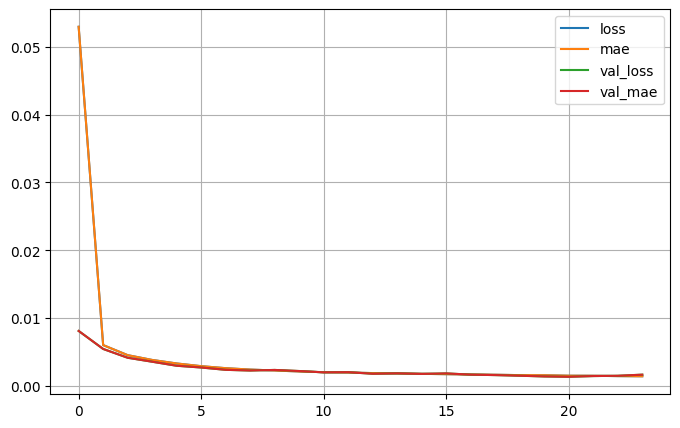

In [17]:
fst_Son, model, Sets_std, scalers_usados = pipeline_refatorado()
model.save('modelo_treinado.keras')
pd.DataFrame(fst_Son.history).plot(figsize=(8, 5))
plt.grid(True)
plt.show()

In [9]:
loss = model.evaluate(Sets_std[2], Sets_std[3])
print(loss*100)

266/266 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step - loss: 0.0278
2.7773283421993256


266/266 ━━━━━━━━━━━━━━━━━━━━ 0s 718us/step
Erro percentual de CD: 1.8%
Erro percentual de T: 2.68%


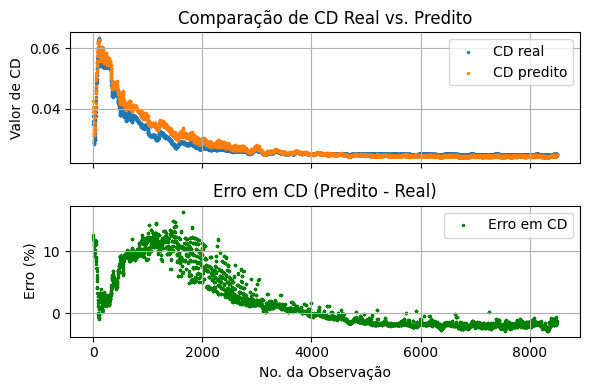

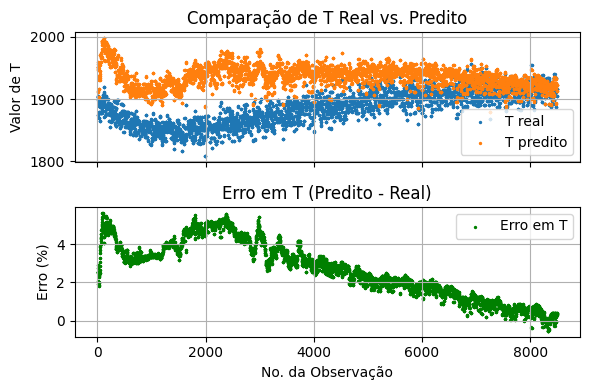

In [20]:
# Roda o pipeline para obter o modelo treinado e os scalers
# model, dados_escalados, scalers = pipeline_refatorado()

# Desempacota o que precisamos
X_train_s, Y_train_s, X_test_s, Y_test_s, X_val_s, Y_val_s = Sets_std
scaler_X, scaler_Y = scalers_usados

# 1. Faz as predições no conjunto de teste (a saída estará na escala de 0 a 1)
Y_pred_s = model.predict(X_test_s)

# 2. Usa o scaler_Y para DESNORMALIZAR tanto as predições quanto os valores reais
Y_pred_desnormalizado = scaler_Y.inverse_transform(Y_pred_s)
Y_test_desnormalizado = scaler_Y.inverse_transform(Y_test_s)


# 3. Agora você pode comparar os valores na escala original!
CD_test = Y_test_desnormalizado[:,0]
T_test = Y_test_desnormalizado[:,1]

CD_pred = Y_pred_desnormalizado[:,0]
T_pred = Y_pred_desnormalizado[:,1]

erroCD = (CD_pred - CD_test)*100/CD_test
erroT = (T_pred - T_test)*100/T_test

print('Erro percentual de CD:', str(round(np.mean(erroCD), 2))+'%')
print('Erro percentual de T:', str(round(np.mean(erroT), 2))+'%')

index = prepara_df('teste')['No. OBS.'].astype(int)

exibe_resultados(index, CD_test, CD_pred, erroCD, T_test, T_pred, erroT)

# Grid Search

In [ ]:
param_grid = {
    'model__neurons': [30, 40, 60],
    'model__optimizer': ['adam'],
    'model__learning_rate': [0.001, 0.0001, 0.00001],
    'batch_size': [16, 32, 64],
    'epochs': [60, 80, 100] # Reduzi para 1 valor para o exemplo rodar mais rápido
}

model_wrapper = KerasRegressor(model=constroi_modelo_tunable, verbose=0)

grid = GridSearchCV(model_wrapper, param_grid=param_grid, scoring='neg_mean_absolute_error', cv=3, n_jobs=-1)

grid_result = grid.fit(X_train_s, Y_train_s)

c:\Users\ymarc\OneDrive\Desktop\ITA - 2025\Mestrado\meVenv3_11\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
# Exibe a melhor combinação de parâmetros encontrada
print("Melhores Parâmetros:")
print(grid_result.best_params_)

# Exibe o melhor score (Erro Absoluto Médio Negativo)
best_score_negativo = grid_result.best_score_
print(f"Melhor Score (MAE Negativo): {best_score_negativo:.4f}")

# Converte para o MAE real para melhor interpretação
melhor_mae = -best_score_negativo
print(f"Isso equivale a um Erro Absoluto Médio (MAE) de: {melhor_mae:.4f}")

Melhores Parâmetros:
{'batch_size': 32, 'epochs': 60, 'model__learning_rate': 0.0001, 'model__neurons': 60, 'model__optimizer': 'adam'}
Melhor Score (MAE Negativo): -0.0009
Isso equivale a um Erro Absoluto Médio (MAE) de: 0.0009


In [19]:
# Guarda o melhor modelo, já treinado e pronto para uso
best_model = grid_result.best_estimator_

# Agora você pode usar este modelo para fazer predições nos seus dados de teste
# (lembre-se de usar os dados de teste escalados, X_test_s)
predictions = scaler_Y.inverse_transform(best_model.predict(X_test_s))

CD_pred = predictions[:,0]
T_pred = predictions[:,1]

# erroCD = CD_pred - CD_test
# erroT = T_pred - T_test
erroCD = (CD_pred - CD_test)*100/CD_test
erroT = (T_pred - T_test)*100/T_test

print('Erro percentual de CD:', str(round(np.mean(erroCD), 2))+'%')
print('Erro percentual de T:', str(round(np.mean(erroT), 2))+'%')

Erro percentual de CD: -2.88%
Erro percentual de T: 5.71%


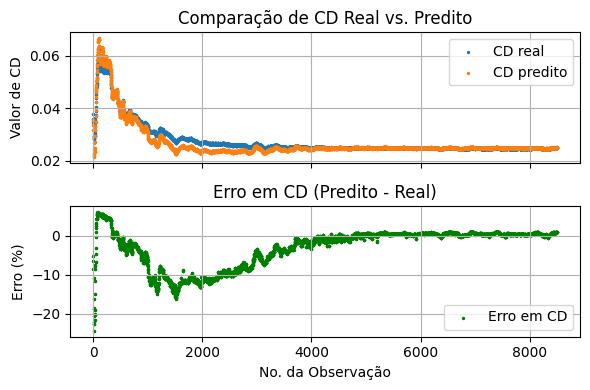

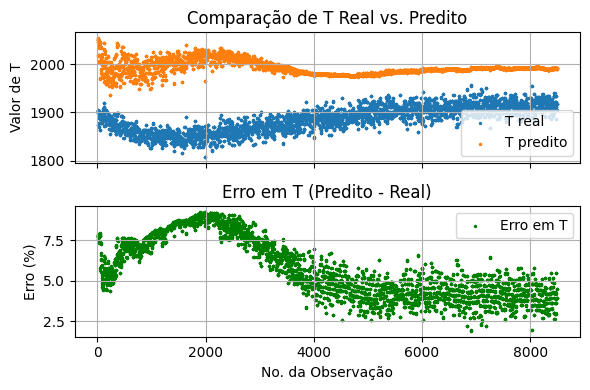

In [20]:
exibe_resultados(index, CD_test, CD_pred, erroCD, T_test, T_pred, erroT)

# Testando os resultados com os dados de treinamento:

In [37]:
print(len(X_train_s))

27196


850/850 ━━━━━━━━━━━━━━━━━━━━ 1s 673us/step
Erro percentual de CD: -0.29%
Erro percentual de T: 0.02%
size index: 33996, size CD_test: 27196, size CD_pred: 27196


ValueError: x and y must be the same size

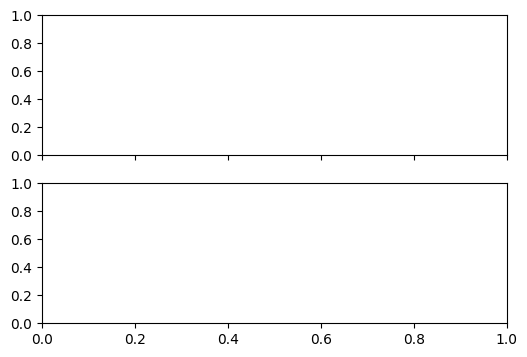

In [33]:
X_train_s, Y_train_s, X_test_s, Y_test_s, X_val_s, Y_val_s = Sets_std
scaler_X, scaler_Y = scalers_usados

# 1. Faz as predições no conjunto de train (a saída estará na escala de 0 a 1)
Y_pred_s = model.predict(X_train_s)

# 2. Usa o scaler_Y para DESNORMALIZAR tanto as predições quanto os valores reais
Y_pred_desnormalizado = scaler_Y.inverse_transform(Y_pred_s)
Y_train_desnormalizado = scaler_Y.inverse_transform(Y_train_s)


# 3. Agora você pode comparar os valores na escala original!
CD_train = Y_train_desnormalizado[:,0]
T_train = Y_train_desnormalizado[:,1]

CD_pred = Y_pred_desnormalizado[:,0]
T_pred = Y_pred_desnormalizado[:,1]

erroCD = (CD_pred - CD_train)*100/CD_train
erroT = (T_pred - T_train)*100/T_train

print('Erro percentual de CD:', str(round(np.mean(erroCD), 2))+'%')
print('Erro percentual de T:', str(round(np.mean(erroT), 2))+'%')

index = prepara_df('treinamento')['No. OBS.'].astype(int)

exibe_resultados(index, CD_train, CD_pred, erroCD, T_train, T_pred, erroT)